In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("HR_Employee_Attrition.csv")
print(df.shape)
df.head()

(5000, 14)


,EmployeeID,Age,Gender,Department,JobRole,MonthlyIncome,OverTime,YearsAtCompany,YearsSinceLastPromotion,JobSatisfaction,WorkLifeBalance,DistanceFromHome,PerformanceRating,Attrition
0,EMP0001,25,Male,Research & Development,Manufacturing Director,13730,No,8,7,4,3,22,3,No
1,EMP0002,52,Female,Research & Development,Research Scientist,6276,No,26,8,4,1,25,4,Yes
2,EMP0003,47,Female,Sales,Sales Executive,6280,No,6,5,3,4,9,3,Yes
3,EMP0004,39,Female,Research & Development,Manufacturing Director,14703,Yes,22,3,1,4,28,3,Yes
4,EMP0005,38,Male,Research & Development,Laboratory Technician,2144,Yes,21,4,4,3,28,3,No


In [6]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.drop(columns=["EmployeeID"])
df["Attrition"] = df["Attrition"].map({"Yes": 1, "No": 0})
df["Attrition"].value_counts()

Missing values: 0
Duplicate rows: 0


Attrition
0    4200
1     800
Name: count, dtype: int64

Attrition rate: 16.0 %


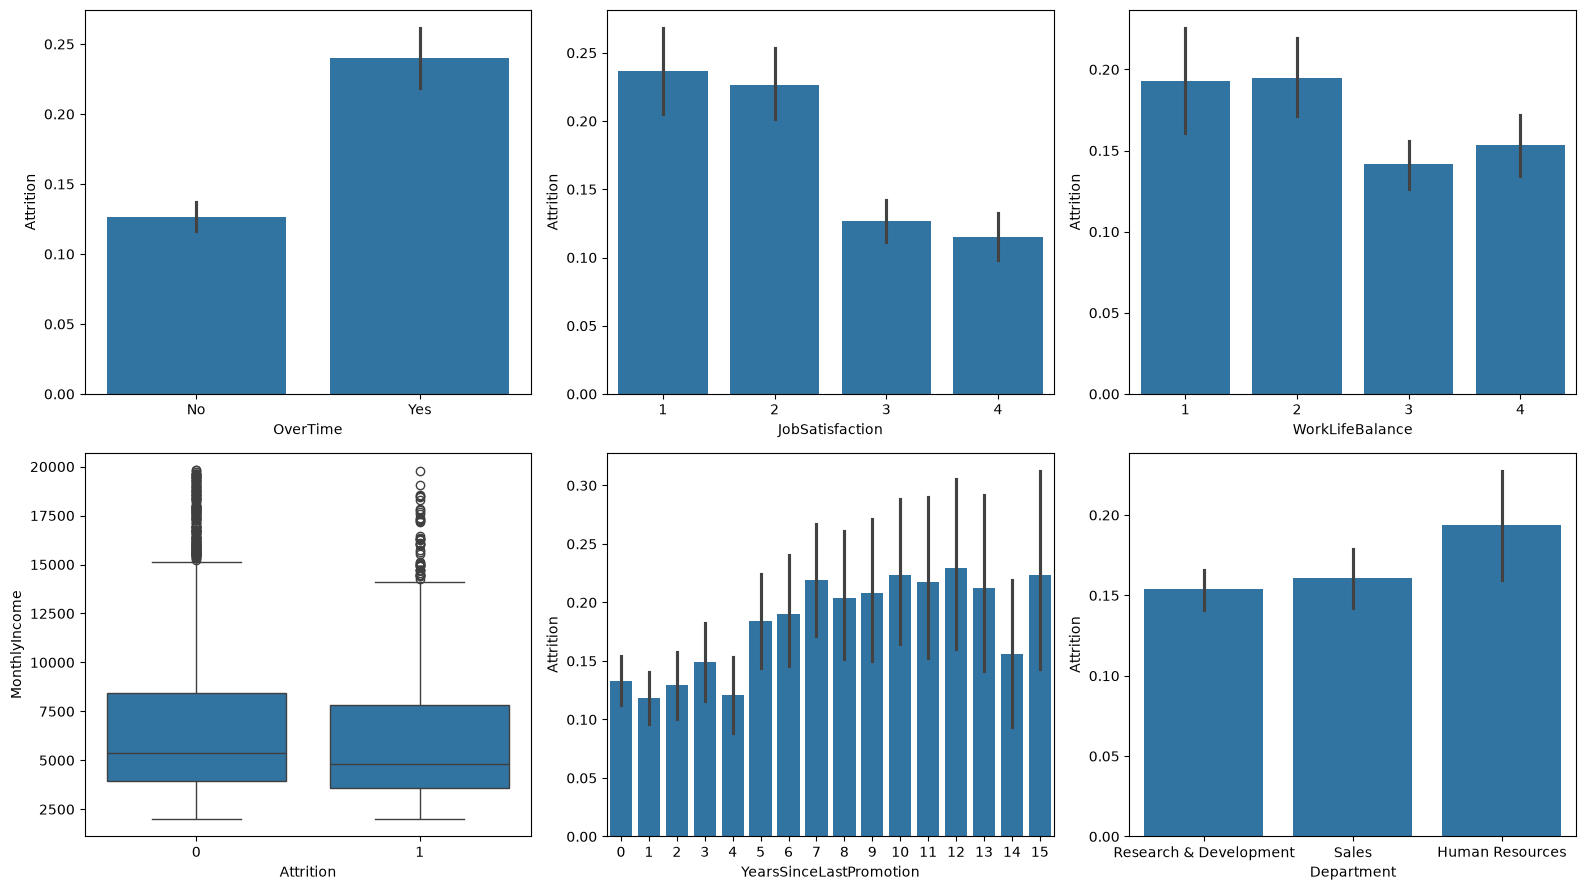

In [15]:
print("Attrition rate:", round(df["Attrition"].mean() * 100, 1), "%")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sns.barplot(x="OverTime", y="Attrition", data=df, ax=axes[0, 0])
sns.barplot(x="JobSatisfaction", y="Attrition", data=df, ax=axes[0, 1])
sns.barplot(x="WorkLifeBalance", y="Attrition", data=df, ax=axes[0, 2])
sns.boxplot(x="Attrition", y="MonthlyIncome", data=df, ax=axes[1, 0])
sns.barplot(x="YearsSinceLastPromotion", y="Attrition", data=df, ax=axes[1, 1])
sns.barplot(x="Department", y="Attrition", data=df, ax=axes[1, 2])
plt.tight_layout()
plt.show()


In [8]:
data = df.copy()

data["OverTime"] = data["OverTime"].map({"Yes": 1, "No": 0})
data["Gender"] = data["Gender"].map({"Male": 1, "Female": 0})
data = pd.get_dummies(data, columns=["Department", "JobRole"], drop_first=True)

X = data.drop(columns=["Attrition"]).astype(float)
y = data["Attrition"]
print(X.shape)
X.head()

(5000, 20)


,Age,Gender,MonthlyIncome,OverTime,YearsAtCompany,YearsSinceLastPromotion,JobSatisfaction,WorkLifeBalance,DistanceFromHome,PerformanceRating,Department_Research & Development,Department_Sales,JobRole_HR Manager,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative
0,25.0,1.0,13730.0,0.0,8.0,7.0,4.0,3.0,22.0,3.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,52.0,0.0,6276.0,0.0,26.0,8.0,4.0,1.0,25.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,47.0,0.0,6280.0,0.0,6.0,5.0,3.0,4.0,9.0,3.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,39.0,0.0,14703.0,1.0,22.0,3.0,1.0,4.0,28.0,3.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,38.0,1.0,2144.0,1.0,21.0,4.0,4.0,3.0,28.0,3.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

num_cols = ["Age", "MonthlyIncome", "YearsAtCompany",
            "YearsSinceLastPromotion", "DistanceFromHome"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (4000, 20) Test: (1000, 20)


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
lr = LogisticRegression(max_iter=1000, class_weight="balanced")
rf = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20,class_weight="balanced", random_state=42)

lr.fit(X_train, y_train)
rf.fit(X_train, y_train)
print("Both models trained Successfully")

Both models trained Successfully


In [12]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, roc_auc_score, confusion_matrix)

models = {"Logistic Regression": lr, "Random Forest": rf}
rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),})

results = pd.DataFrame(rows).round(3).set_index("Model")
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.63,0.227,0.544,0.32,0.647
Random Forest,0.66,0.235,0.500,0.32,0.651


In [17]:
X_all = X.copy()
X_all[num_cols] = scaler.transform(X[num_cols])

risk = df.copy()
risk["LeaveProbability"] = rf.predict_proba(X_all)[:, 1].round(3)
risk["RiskLevel"] = pd.qcut(risk["LeaveProbability"].rank(method="first"),
                            [0, 0.55, 0.85, 1], labels=["Low", "Medium", "High"])
risk["Attrition"] = risk["Attrition"].map({1: "Yes", 0: "No"})

print(risk["RiskLevel"].value_counts())
print(risk.groupby("RiskLevel")["Attrition"].apply(lambda x: (x == "Yes").mean()).round(3))

RiskLevel
Low       2750
Medium    1500
High       750
Name: count, dtype: int64
RiskLevel
Low       0.075
Medium    0.188
High      0.415
Name: Attrition, dtype: float64


In [ ]:
# Top reasons
importance = pd.Series(rf.feature_importances_,index=X.columns).sort_values(ascending=False)

print("Top 10 Reasons for Attrition:")
for factor, score in importance.head(10).items():
    print(f"{factor}: {score:.3f}")

Top 10 Reasons for Attrition:
OverTime: 0.198
JobSatisfaction: 0.185
YearsSinceLastPromotion: 0.150
MonthlyIncome: 0.120
YearsAtCompany: 0.087
Age: 0.072
DistanceFromHome: 0.066
WorkLifeBalance: 0.038
JobRole_Laboratory Technician: 0.014
JobRole_Research Scientist: 0.011
